# Custom PatchCore — No-Anomaly vs Anomaly

**Unsupervised** anomaly detection: the model only ever sees healthy panels.

1. A backbone turns each image into a grid of patch vectors.
2. The patches of the **training No-Anomaly images** form a *memory bank*, reduced with **PCA** and then subsampled (greedy coreset).
3. At test time, each patch looks up its nearest neighbour in the memory bank (**faiss**). The image score is the largest of these distances: a patch that resembles nothing known = anomaly.
4. The threshold is chosen on the validation set, then evaluation goes through `scripts/evaluation.py`: same metrics as the binary CNN, in the same MLflow experiment.

## Why not ResNet

The images are **40×24 px, grayscale, thermal**. An ImageNet ResNet expects 224×224 RGB: the images would need ×6 upscaling (the network would mostly see interpolation artefacts) and a duplicated channel. Above all, its `layer2`/`layer3` layers (the ones PatchCore uses) have a stride of 8-16: at the original resolution only a 5×3 or 3×2 patch grid would remain, too coarse to localise a hot cell.

## Proposed backbones (`BACKBONE`)

| Backbone | Idea | Pros / cons |
|---|---|---|
| `"autoencoder"` **(recommended)** | Denoising convolutional autoencoder trained **on the training No-Anomaly images only**, at the native 40×24×1 size | Stays 100% unsupervised, like PatchCore. The features are not pre-trained on a large corpus, so they are less rich. |
| `"simplecnn"` | Encoder of the `SimpleCNN` from the best `custom_cnn_multi` run (loaded from MLflow) | Features tailored to these images and discriminative. **But it has seen the anomaly labels** → no longer unsupervised; read it as an upper bound. |
| `"pixels"` | Raw 8×8 pixel patches, no network | Minimal reference: if a backbone does not beat it, it adds nothing. |

Pre-trained options not implemented, if needed later: **EfficientNet-B0 / MobileNetV3** (same scale problems as ResNet, but lighter), **DINOv2 ViT-S/14** with ×6 upscaling (14 px patches, very generic features).

In [1]:
import os
import sys
import time
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

import faiss
import joblib
import mlflow
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
from evaluation import run_evaluation, find_threshold, compare_runs

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device} | faiss {faiss.__version__}")

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

d:\Computer Vision Engineer\infrared-solar\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda | faiss 1.15.1


In [2]:
BACKBONE = "autoencoder"

PCA_DIM = 64
CORESET_RATIO = 0.10
K_NEIGHBORS = 1

AE_EPOCHS = 30
AE_NOISE_STD = 0.1

SIMPLECNN_EXPERIMENT = "infrared-solar-custom-cnn"
SIMPLECNN_RUN_ID = None

EXPERIMENT_NAME = "infrared-solar-custom-cnn-binary"
RUN_NAME = f"patchcore-{BACKBONE}-pca{PCA_DIM}-core{CORESET_RATIO}"

In [3]:
DATA_DIR = os.path.join("..", "data")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

def to_binary(df):
    df = df.copy()
    df["label_orig"] = df["label"]
    df["label"] = np.where(df["label"] == "No-Anomaly", "No-Anomaly", "Anomaly")
    return df

train, val, test = to_binary(train), to_binary(val), to_binary(test)

classes = ["No-Anomaly", "Anomaly"]
label2idx = {c: i for i, c in enumerate(classes)}

train_normal = train[train["label"] == "No-Anomaly"].reset_index(drop=True)

print(f"Healthy train (memory bank) : {len(train_normal)}")
print(f"Val  : {len(val)}  ({(val['label'] == 'Anomaly').sum()} anomalies) -> threshold selection")
print(f"Test : {len(test)} ({(test['label'] == 'Anomaly').sum()} anomalies)")

Train sain (memory bank) : 6398
Val  : 3195  (dont 1595 anomalies) -> choix du seuil
Test : 3994 (dont 1995 anomalies)


In [4]:
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

ae_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])


class CreateDataset(Dataset):
    def __init__(self, dataframe, transform=None, label2idx=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label2idx = label2idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row["filepath"]).convert("L")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.label2idx[row["label"]], dtype=torch.long)


memory_loader = DataLoader(CreateDataset(train_normal, eval_transform, label2idx), batch_size=256, shuffle=False)
ae_loader = DataLoader(CreateDataset(train_normal, ae_transform, label2idx), batch_size=128, shuffle=True)
val_loader = DataLoader(CreateDataset(val, eval_transform, label2idx), batch_size=256, shuffle=False)
test_loader = DataLoader(CreateDataset(test, eval_transform, label2idx), batch_size=256, shuffle=False)

images, _ = next(iter(memory_loader))
print(images.shape)

torch.Size([256, 1, 40, 24])


## Backbones

Each backbone exposes `features(x)`, which returns a **list of feature maps** (intermediate levels, like `layer2` + `layer3` in PatchCore). All of them have a 10×6 or 5×3 grid: one cell of the 10×6 grid covers 4×4 px of the image.

In [5]:
def conv_block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
        nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class ConvAutoencoder(nn.Module):
    def __init__(self, latent_ch=16):
        super().__init__()
        self.enc1 = conv_block(1, 32)
        self.enc2 = conv_block(32, 64)
        self.enc3 = conv_block(64, 128)
        self.bottleneck = nn.Conv2d(128, latent_ch, 1)

        def up(i, o):
            return nn.Sequential(nn.ConvTranspose2d(i, o, 2, stride=2), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())

        self.decoder = nn.Sequential(
            nn.Conv2d(latent_ch, 128, 1), nn.ReLU(),
            up(128, 64),
            up(64, 32),
            up(32, 16),
            nn.Conv2d(16, 1, 3, padding=1), nn.Tanh(),
        )

    def forward(self, x):
        return self.decoder(self.bottleneck(self.enc3(self.enc2(self.enc1(x)))))

    def features(self, x):
        f2 = self.enc2(self.enc1(x))
        return [f2, self.enc3(f2)]


def train_autoencoder(model, loader, epochs, noise_std):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for x, _ in loader:
            x = x.to(device)
            recon = model(x + noise_std * torch.randn_like(x))
            loss = F.mse_loss(recon, x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)
        scheduler.step()
        history.append(total / len(loader.dataset))
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"AE epoch [{epoch+1}/{epochs}] mse: {history[-1]:.5f}")
    return history


class PixelPatches(nn.Module):
    def features(self, x):
        b = x.shape[0]
        patches = F.unfold(x, kernel_size=8, stride=4, padding=2)
        return [patches.view(b, 64, 10, 6)]


class SimpleCNN(nn.Module):
    def __init__(self, n_classes=12, in_ch=1):
        super().__init__()

        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.MaxPool2d(2)]

        self.features = nn.Sequential(*block(in_ch, 32), *block(32, 64), *block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d((5, 3))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128 * 5 * 3, n_classes))

    def forward(self, x):
        return self.head(self.pool(self.features(x)).flatten(1))


class SequentialTaps(nn.Module):
    def __init__(self, seq, taps):
        super().__init__()
        self.seq, self.taps = seq, set(taps)

    def features(self, x):
        out = []
        for i, layer in enumerate(self.seq):
            x = layer(x)
            if i in self.taps:
                out.append(x)
        return out

AE epoch [1/30] mse: 0.02351
AE epoch [6/30] mse: 0.00311
AE epoch [11/30] mse: 0.00314
AE epoch [16/30] mse: 0.00249
AE epoch [21/30] mse: 0.00217
AE epoch [26/30] mse: 0.00184
AE epoch [30/30] mse: 0.00179


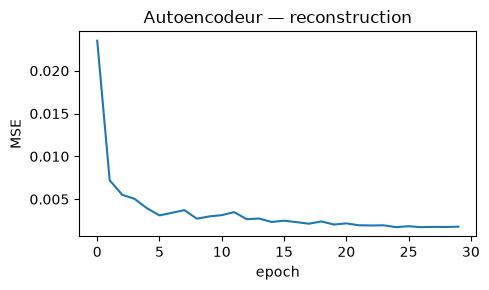

(2, 64, 10, 6)
(2, 128, 5, 3)


In [6]:
backbone_params, backbone_metrics = {}, {}

if BACKBONE == "autoencoder":
    backbone = ConvAutoencoder().to(device)
    t0 = time.time()
    ae_history = train_autoencoder(backbone, ae_loader, AE_EPOCHS, AE_NOISE_STD)
    backbone_params.update({"ae_epochs": AE_EPOCHS, "ae_noise_std": AE_NOISE_STD, "ae_latent_ch": 16})
    backbone_metrics.update({"ae_final_mse": ae_history[-1], "ae_train_time_s": time.time() - t0})

    plt.figure(figsize=(5, 3))
    plt.plot(ae_history)
    plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Autoencoder reconstruction")
    plt.tight_layout(); plt.show()

elif BACKBONE == "simplecnn":
    run_id = SIMPLECNN_RUN_ID
    if run_id is None:
        runs = compare_runs(SIMPLECNN_EXPERIMENT)
        if runs.empty:
            raise RuntimeError(f"No run in {SIMPLECNN_EXPERIMENT}: run custom_cnn_multi first.")
        run_id = runs.iloc[0]["run_id"]
    cnn = mlflow.pytorch.load_model(f"runs:/{run_id}/model", map_location=device)
    backbone = SequentialTaps(cnn.features, taps=[13, 20]).to(device)
    backbone_params.update({"simplecnn_run_id": run_id})
    print(f"SimpleCNN loaded from run {run_id}")

elif BACKBONE == "pixels":
    backbone = PixelPatches().to(device)

else:
    raise ValueError(f"Unknown BACKBONE: {BACKBONE}")

backbone.eval()
with torch.no_grad():
    for f in backbone.features(images[:2].to(device)):
        print(tuple(f.shape))

## Memory bank

For each patch: **3×3 local averaging** (each vector also sees its neighbours, as in PatchCore), then the deeper levels are upsampled to the finest grid and concatenated.

In [7]:
@torch.no_grad()
def extract_patches(loader):
    backbone.eval()
    out = []
    for x, _ in loader:
        maps = backbone.features(x.to(device))
        size = maps[0].shape[-2:]
        maps = [F.avg_pool2d(m, 3, stride=1, padding=1) for m in maps]
        maps = [m if m.shape[-2:] == size else F.interpolate(m, size=size, mode="bilinear", align_corners=False)
                for m in maps]
        out.append(torch.cat(maps, dim=1).permute(0, 2, 3, 1).cpu())
    return torch.cat(out).numpy().astype(np.float32)


t0 = time.time()
memory_raw = extract_patches(memory_loader)
N_IMG, H, W, D_RAW = memory_raw.shape
memory_raw = memory_raw.reshape(-1, D_RAW)
print(f"Grid {H}×{W}, {D_RAW} dims -> {len(memory_raw):,} healthy patches ({time.time() - t0:.1f}s)")

Grille 10×6, 192 dims -> 383,880 patchs sains (4.4s)


In [8]:
pca_dim = min(PCA_DIM, D_RAW)
fit_idx = np.random.choice(len(memory_raw), size=min(200_000, len(memory_raw)), replace=False)
pca = PCA(n_components=pca_dim, random_state=SEED).fit(memory_raw[fit_idx])
explained = pca.explained_variance_ratio_.sum()
print(f"PCA {D_RAW} -> {pca_dim} dims : {explained:.1%} variance retained")

memory = pca.transform(memory_raw).astype(np.float32)
del memory_raw

PCA 192 -> 64 dims : 99.6% de variance conservée


In [9]:
@torch.no_grad()
def greedy_coreset(x, n, proj_dim=128):
    x = torch.from_numpy(x).to(device)
    if x.shape[1] > proj_dim:
        x = x @ torch.randn(x.shape[1], proj_dim, device=device) / proj_dim ** 0.5
    sq = (x * x).sum(1)
    selected = torch.empty(n, dtype=torch.long, device=device)
    selected[0] = np.random.randint(len(x))
    min_dist = sq - 2 * (x @ x[selected[0]]) + sq[selected[0]]
    for k in range(1, n):
        selected[k] = torch.argmax(min_dist)
        min_dist = torch.minimum(min_dist, sq - 2 * (x @ x[selected[k]]) + sq[selected[k]])
    return selected.cpu().numpy()


t0 = time.time()
if CORESET_RATIO < 1.0:
    n_keep = max(1, int(len(memory) * CORESET_RATIO))
    memory_bank = memory[greedy_coreset(memory, n_keep)]
else:
    memory_bank = memory
coreset_time = time.time() - t0
print(f"Memory bank : {len(memory_bank):,} patches ({coreset_time:.1f}s)")

index = faiss.IndexFlatL2(memory_bank.shape[1])
index.add(np.ascontiguousarray(memory_bank))

Memory bank : 38,388 patchs (21.7s)


In [10]:
def score_loader(loader):
    patches = extract_patches(loader)
    n, h, w, d = patches.shape
    feats = pca.transform(patches.reshape(-1, d)).astype(np.float32)
    dist, _ = index.search(np.ascontiguousarray(feats), K_NEIGHBORS)
    patch_scores = np.sqrt(np.maximum(dist, 0)).mean(1)
    maps = patch_scores.reshape(n, h, w)
    labels = np.array([label2idx[l] for l in loader.dataset.dataframe["label"]])
    return maps.max(axis=(1, 2)), maps, labels


val_scores, val_maps, val_labels = score_loader(val_loader)

t0 = time.time()
test_scores, test_maps, test_labels = score_loader(test_loader)
infer_ms = 1000 * (time.time() - t0) / len(test_scores)

threshold = find_threshold(val_labels, val_scores)
val_auc = roc_auc_score(val_labels, val_scores)
print(f"Val AUC : {val_auc:.4f} | threshold (max val F1) : {threshold:.4f} | {infer_ms:.2f} ms/image")

Val AUC : 0.8408 | seuil (F1 max sur val) : 1.5049 | 4.20 ms/image


In [11]:
result = run_evaluation(
    test_labels, test_scores,
    classes=classes,
    experiment_name=EXPERIMENT_NAME,
    run_name=RUN_NAME,
    threshold=threshold,
    dataframe=test,
    params={
        "model": "PatchCore",
        "backbone": BACKBONE,
        "feature_grid": f"{H}x{W}",
        "feature_dim_raw": D_RAW,
        "pca_dim": pca_dim,
        "coreset_ratio": CORESET_RATIO,
        "memory_bank_size": len(memory_bank),
        "k_neighbors": K_NEIGHBORS,
        "n_train_normal": len(train_normal),
        "threshold_source": "val_f1_max",
        "seed": SEED,
        **backbone_params,
    },
    tags={"dataset": "dataset_eda", "task": "binary", "stage": "patchcore"},
    extra_metrics={
        "val_roc_auc": val_auc,
        "pca_explained_variance": explained,
        "coreset_time_s": coreset_time,
        "inference_ms_per_image": infer_ms,
        **backbone_metrics,
    },
)

with mlflow.start_run(run_id=result["run_id"]), tempfile.TemporaryDirectory() as tmp:
    torch.save(backbone.state_dict(), os.path.join(tmp, "backbone.pt"))
    joblib.dump(pca, os.path.join(tmp, "pca.joblib"))
    faiss.write_index(index, os.path.join(tmp, "memory_bank.faiss"))
    mlflow.log_artifacts(tmp, artifact_path="patchcore")

===== TEST =====
test_accuracy          : 0.7584
test_f1_macro          : 0.7584
test_f1_weighted       : 0.7584
test_roc_auc           : 0.8346
test_precision_Anomaly : 0.7596
test_recall_Anomaly    : 0.7554
test_threshold         : 1.5049

              precision    recall  f1-score   support

  No-Anomaly       0.76      0.76      0.76      1999
     Anomaly       0.76      0.76      0.76      1995

    accuracy                           0.76      3994
   macro avg       0.76      0.76      0.76      3994
weighted avg       0.76      0.76      0.76      3994


Run MLflow : 839ba7c402e7433eba615ddd4d9d2556
Visualiser : mlflow ui --backend-store-uri "sqlite:///D:/Computer Vision Engineer/infrared-solar/mlflow.db"


AUC ROC           : 0.8346
Précision Anomaly : 0.7596
Rappel Anomaly    : 0.7554


pred,No-Anomaly,Anomaly
true,,
No-Anomaly,1522,477
Anomaly,488,1507


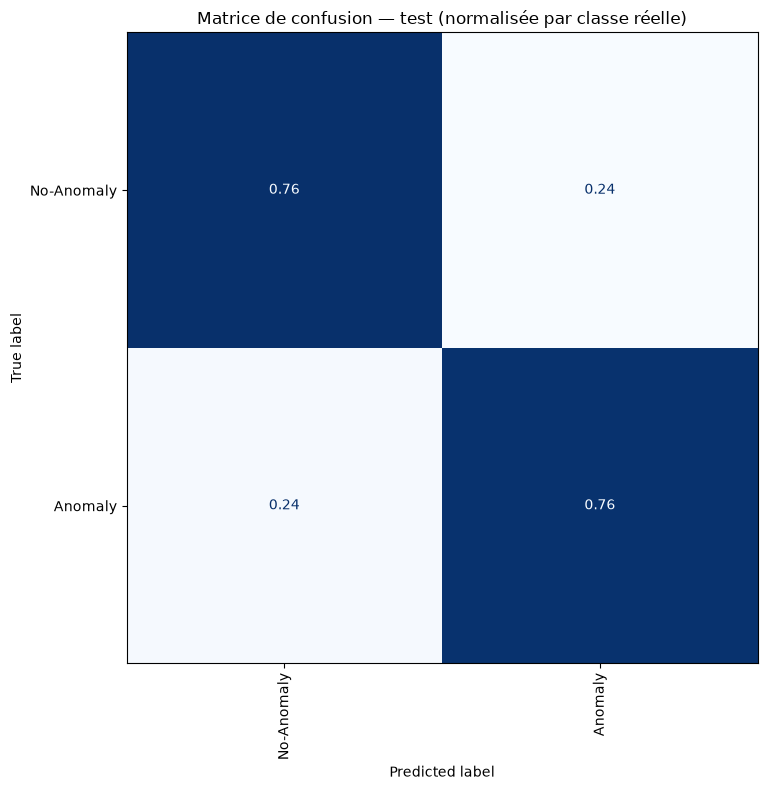

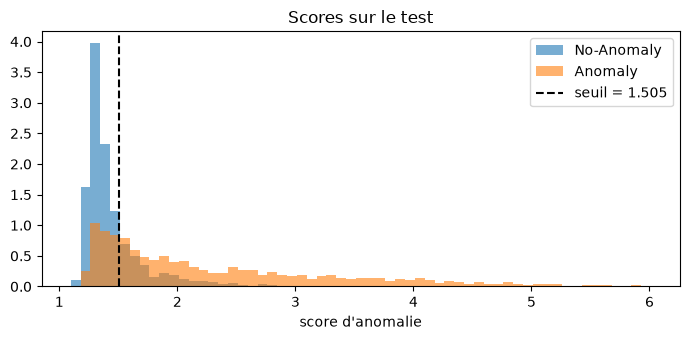

In [12]:
m = result["metrics"]
print(f"ROC AUC           : {result['roc_auc']['global']:.4f}")
print(f"Anomaly precision : {m['test_precision_Anomaly']:.4f}")
print(f"Anomaly recall    : {m['test_recall_Anomaly']:.4f}")
display(result["confusion_matrix"])
display(result["figure"])

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(test_scores.min(), np.percentile(test_scores, 99.5), 60)
for i, cls in enumerate(classes):
    ax.hist(test_scores[test_labels == i], bins=bins, alpha=0.6, label=cls, density=True)
ax.axvline(threshold, color="k", ls="--", label=f"threshold = {threshold:.3f}")
ax.set_xlabel("anomaly score"); ax.legend(); ax.set_title("Test scores")
plt.tight_layout(); plt.show()

In [13]:
preds = result["predictions"]
correct = preds[preds["correct"]]
errors = preds[~preds["correct"]]
print(f"Correct : {len(correct)} | Errors : {len(errors)}")

anomalies = preds[preds["label"] == "Anomaly"]
display(anomalies.groupby("label_orig")
        .agg(n=("correct", "size"), recall=("correct", "mean"), score_median=("score", "median"))
        .sort_values("recall"))

false_positives = errors[errors["label"] == "No-Anomaly"].sort_values("score", ascending=False)
false_negatives = errors[errors["label"] == "Anomaly"].sort_values("score")
print(f"False positives : {len(false_positives)} | False negatives : {len(false_negatives)}")
display(false_negatives[["filepath", "label_orig", "score"]].head(10))

Bons : 3029 | Erreurs : 965


,n,rappel,score_median
label_orig,,,
Hot-Spot,50,0.380000,1.414768
Shadowing,209,0.511962,1.516831
Cell,375,0.664000,1.677954
Offline-Module,165,0.666667,1.746841
Diode,299,0.792642,1.900769
Hot-Spot-Multi,49,0.795918,1.897111
Vegetation,328,0.804878,2.212286
Soiling,40,0.850000,2.878354
Diode-Multi,35,0.885714,2.008351


Faux positifs : 477 | Faux négatifs : 488


,filepath,label_orig,score
2835,d:\Computer Vision Engineer\infrared-solar\dat...,Cell,1.166953
781,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.169456
1153,d:\Computer Vision Engineer\infrared-solar\dat...,Vegetation,1.182633
245,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.194695
1902,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.194796
2522,d:\Computer Vision Engineer\infrared-solar\dat...,Cell,1.199664
1633,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.201056
944,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.212615
2352,d:\Computer Vision Engineer\infrared-solar\dat...,Shadowing,1.213279
3886,d:\Computer Vision Engineer\infrared-solar\dat...,Vegetation,1.215707


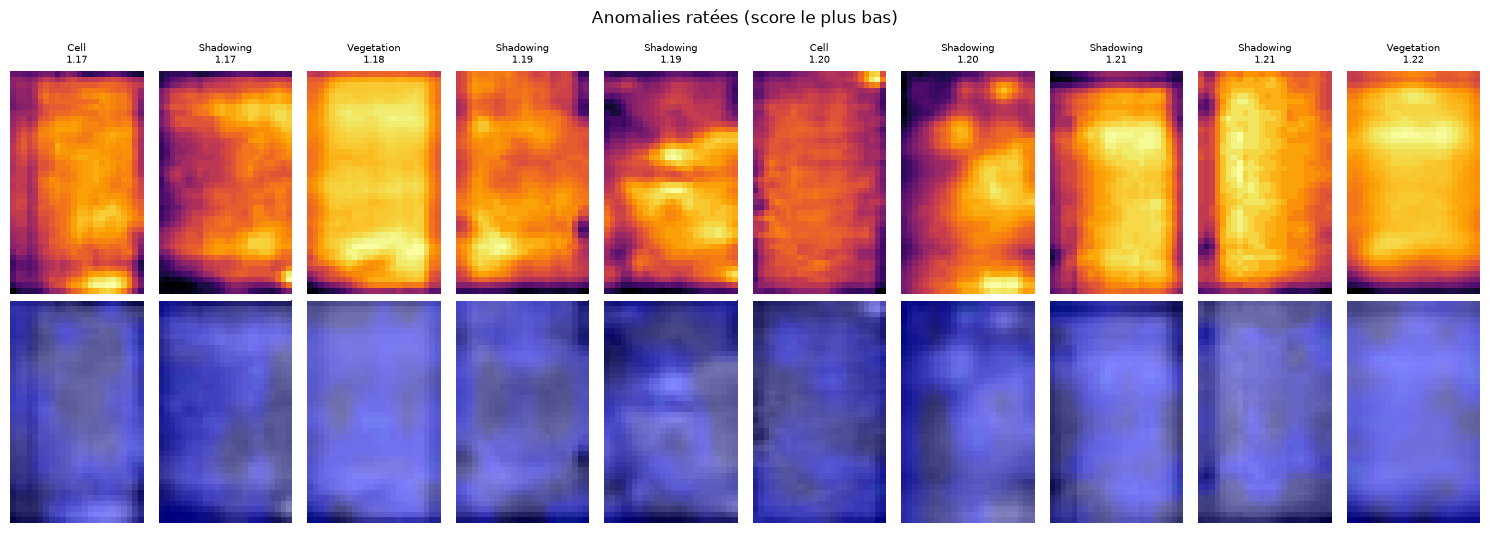

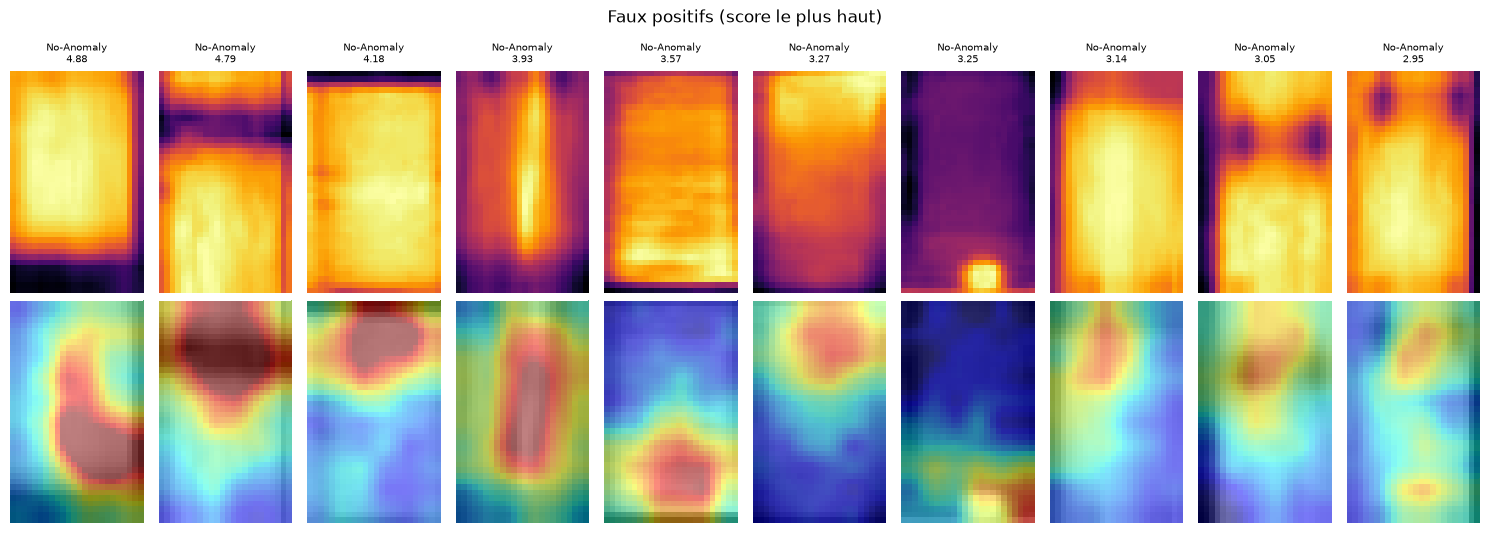

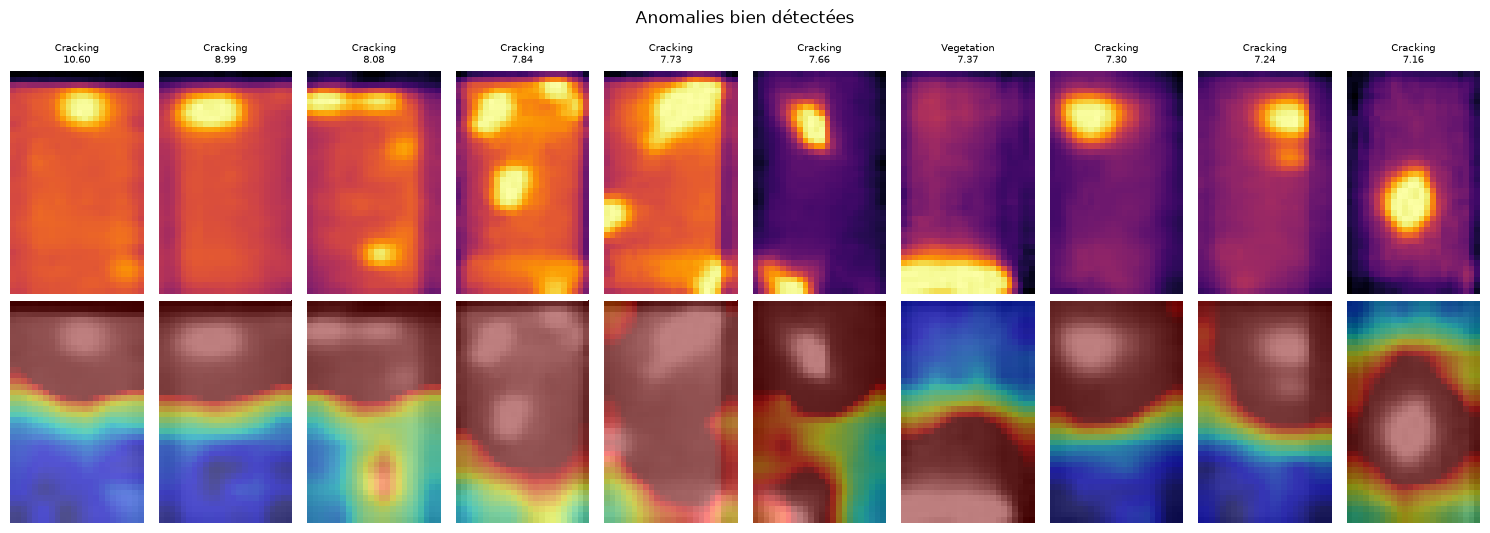

In [14]:
VMAX = np.percentile(test_maps, 99)

def show_anomaly_maps(df, n=10, title=""):
    df = df.head(n)
    if df.empty:
        return
    fig, axes = plt.subplots(2, len(df), figsize=(1.5 * len(df), 5.5), squeeze=False)
    for j, (i, r) in enumerate(df.iterrows()):
        img = Image.open(r["filepath"]).convert("L")
        heatmap = F.interpolate(torch.from_numpy(test_maps[i])[None, None], size=(40, 24),
                                mode="bilinear", align_corners=False)[0, 0].numpy()
        axes[0, j].imshow(img, cmap="inferno")
        axes[0, j].set_title(f"{r['label_orig']}\n{r['score']:.2f}", fontsize=7)
        axes[1, j].imshow(img, cmap="gray")
        axes[1, j].imshow(heatmap, cmap="jet", alpha=0.5, vmin=threshold * 0.5, vmax=VMAX)
        for ax in axes[:, j]:
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_anomaly_maps(false_negatives, title="Missed anomalies (lowest scores)")
show_anomaly_maps(false_positives, title="False positives (highest scores)")
show_anomaly_maps(correct[correct["label"] == "Anomaly"].sort_values("score", ascending=False),
                  title="Correctly detected anomalies")

In [15]:
print(compare_runs(EXPERIMENT_NAME).to_string(index=False))

                          run_id                           tags.mlflow.runName  metrics.best_val_f1_macro  metrics.test_f1_macro  metrics.test_roc_auc  metrics.test_accuracy params.model params.lr params.num_epochs                       start_time
f808f9af2d344e3dae70e24a6952c16e                 simplecnn-binary-weighted-aug                   0.922334               0.924592              0.971272               0.924637    SimpleCNN     0.001                30 2026-10-07 17:16:59.734000+00:00
b53b37537fc042898ed73362210caf42 simplecnn-binary-weighted-aug-cleanlab-pruned                   0.921048               0.923301              0.968001               0.923385    SimpleCNN     0.001                30 2026-10-07 20:00:37.302000+00:00
e3b730f6d7da4ca58cfe187e82ab38fb                 simplecnn-binary-weighted-aug                   0.923265               0.922826              0.970181               0.922884    SimpleCNN     0.001                30 2026-10-07 19:33:41.837000+00:00
839ba7c4